# Demo · Fundamentos de NLP

**Tema 2 · Sesión 4 · Máster en Ingeniería de Automatización con IA Agéntica · EBIS**

Este notebook tiene dos usos en clase:

- **Mini-demo en el bloque 2** (slide 9): solo la sección 1 (tokenización con tiktoken). 3 minutos.
- **Demo de cierre** (slide 25): secciones 2, 3 y 4 — embeddings, aritmética semántica y visualización. 10 minutos.

Estructura:

1. **Tokenización** con `tiktoken` — cómo GPT-4 trocea el texto.
2. **Embeddings de frase** con `sentence-transformers` — significado convertido en geometría.
3. **Aritmética semántica** con GloVe — la analogía rey/reina en directo.
4. **Visualización 2D** con PCA — ver los embeddings con los ojos.

> ⏱ Ejecución completa: ~3 min · 🧰 Requisitos: Python 3.10+, MacBook M4 (o cualquier máquina con 4 GB de RAM libres).

## Setup · Instalación y verificación

Si es la primera vez que ejecutas este notebook, descomenta y ejecuta la celda siguiente.

In [1]:
%pip install -q tiktoken sentence-transformers gensim scikit-learn matplotlib numpy


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, platform

print(f"Python  : {sys.version.split()[0]}")
print(f"Sistema : {platform.system()} {platform.release()}")
print(f"CPU     : {platform.machine()}")

apple_silicon = platform.system() == "Darwin" and platform.machine() == "arm64"
print(f"\nApple Silicon: {'✅ sí (acelerado con MPS)' if apple_silicon else '⚠️  no (funcionará pero más lento)'}")

Python  : 3.11.15
Sistema : Linux 7.0.0-22-generic
CPU     : x86_64

Apple Silicon: ⚠️  no (funcionará pero más lento)


---

# 1 · Tokenización con `tiktoken`

> Esta sección es la del **mini-demo en el slide 9** del bloque "De letras a números".

`tiktoken` es la librería oficial de OpenAI para tokenizar exactamente como lo hacen los modelos GPT. En 3 líneas vemos qué pasa por debajo cuando llamamos a una API de LLM.

In [17]:
import tiktoken

# Tokenizador de GPT-4 / GPT-4o (cl100k_base)
enc = tiktoken.encoding_for_model("gpt-4")

frase = "Hola mundo, soy un LLM."
frase2 = "Hi world, I am a LLM."
ids = enc.encode(frase)
ids2 = enc.encode(frase2)

print(f"Frase   : '{frase}'")
print(f"Tokens  : {len(ids)}")
print(f"IDs     : {ids}")

print(f"Frase   : '{frase2}'")
print(f"Tokens  : {len(ids2)}")
print(f"IDs     : {ids2}")

Frase   : 'Hola mundo, soy un LLM.'
Tokens  : 8
IDs     : [69112, 29452, 11, 29839, 653, 445, 11237, 13]
Frase   : 'Hi world, I am a LLM.'
Tokens  : 9
IDs     : [13347, 1917, 11, 358, 1097, 264, 445, 11237, 13]


### Ver los tokens uno a uno

Decodificamos cada ID para ver qué fragmento de texto representa. Observad cómo "Hola" es un token entero pero "LLM" se trocea.

In [4]:
def mostrar_tokens(frase, encoder=enc):
    ids = encoder.encode(frase)
    print(f"\n'{frase}'")
    print(f"→ {len(ids)} tokens:")
    for i, token_id in enumerate(ids):
        token_bytes = encoder.decode_single_token_bytes(token_id)
        try:
            token_str = token_bytes.decode('utf-8')
        except UnicodeDecodeError:
            token_str = repr(token_bytes)
        print(f"  [{i:2d}] ID={token_id:6d}  →  {repr(token_str)}")

mostrar_tokens("Hola mundo, soy un LLM.")


'Hola mundo, soy un LLM.'
→ 8 tokens:
  [ 0] ID= 69112  →  'Hola'
  [ 1] ID= 29452  →  ' mundo'
  [ 2] ID=    11  →  ','
  [ 3] ID= 29839  →  ' soy'
  [ 4] ID=   653  →  ' un'
  [ 5] ID=   445  →  ' L'
  [ 6] ID= 11237  →  'LM'
  [ 7] ID=    13  →  '.'


### Comparativa Español vs Inglés

Misma idea, dos idiomas. El inglés "comprime" mucho mejor: menos tokens para decir lo mismo.

> Implicación práctica: una conversación en español cuesta **alrededor de un 50% más** que la misma en inglés en una API de OpenAI.

In [5]:
frases = [
    ("ES", "El procesamiento del lenguaje natural es fascinante."),
    ("EN", "Natural language processing is fascinating."),
    ("ES", "Esternocleidomastoideo."),
    ("EN", "Antidisestablishmentarianism."),
    ("ES", "¡Hola! 👋 ¿Cómo estás? 😀"),
    ("EN", "Muchas gracias!"),
    ("ES", "Thanks a lot!"),
]

for idioma, frase in frases:
    n_tokens = len(enc.encode(frase))
    n_palabras = len(frase.split())
    ratio = n_tokens / n_palabras if n_palabras > 0 else 0
    print(f"[{idioma}] {frase!r:60} → {n_tokens:2d} tokens ({n_palabras} palabras, {ratio:.2f} tok/palabra)")

[ES] 'El procesamiento del lenguaje natural es fascinante.'       → 13 tokens (7 palabras, 1.86 tok/palabra)
[EN] 'Natural language processing is fascinating.'                →  6 tokens (5 palabras, 1.20 tok/palabra)
[ES] 'Esternocleidomastoideo.'                                    →  9 tokens (1 palabras, 9.00 tok/palabra)
[EN] 'Antidisestablishmentarianism.'                              →  7 tokens (1 palabras, 7.00 tok/palabra)
[ES] '¡Hola! 👋 ¿Cómo estás? 😀'                                    → 11 tokens (5 palabras, 2.20 tok/palabra)
[EN] 'Muchas gracias!'                                            →  4 tokens (2 palabras, 2.00 tok/palabra)
[ES] 'Thanks a lot!'                                              →  4 tokens (3 palabras, 1.33 tok/palabra)


### Casos divertidos · palabras técnicas, emojis y código

Cualquier texto del mundo es representable, pero la eficiencia varía.

In [6]:
casos = [
    "tokenización",
    "Schnauzer",
    "🦄🌈✨",
    "def hello():\n    print('hi')",
    "0xDEADBEEF",
]

for caso in casos:
    mostrar_tokens(caso)


'tokenización'
→ 2 tokens:
  [ 0] ID=  5963  →  'token'
  [ 1] ID= 42600  →  'ización'

'Schnauzer'
→ 4 tokens:
  [ 0] ID=    50  →  'S'
  [ 1] ID=  2174  →  'chn'
  [ 2] ID=  2933  →  'au'
  [ 3] ID=  7215  →  'zer'

'🦄🌈✨'
→ 8 tokens:
  [ 0] ID=  9468  →  "b'\\xf0\\x9f'"
  [ 1] ID=    99  →  "b'\\xa6'"
  [ 2] ID=   226  →  "b'\\x84'"
  [ 3] ID=  9468  →  "b'\\xf0\\x9f'"
  [ 4] ID=   234  →  "b'\\x8c'"
  [ 5] ID=   230  →  "b'\\x88'"
  [ 6] ID= 38798  →  "b'\\xe2\\x9c'"
  [ 7] ID=   101  →  "b'\\xa8'"

'def hello():
    print('hi')'
→ 8 tokens:
  [ 0] ID=   755  →  'def'
  [ 1] ID= 24748  →  ' hello'
  [ 2] ID=  4019  →  '():\n'
  [ 3] ID=   262  →  '   '
  [ 4] ID=  1194  →  ' print'
  [ 5] ID=   493  →  "('"
  [ 6] ID=  6151  →  'hi'
  [ 7] ID=   873  →  "')"

'0xDEADBEEF'
→ 5 tokens:
  [ 0] ID=    15  →  '0'
  [ 1] ID= 80079  →  'xDE'
  [ 2] ID= 95473  →  'ADB'
  [ 3] ID=  7244  →  'EE'
  [ 4] ID=    37  →  'F'


> **🛑 Pausa de mini-demo aquí.** Si estás en el slide 9 de la sesión, vuelve a las slides. Continúa con el notebook cuando llegues al slide 25.

---

# 2 · Embeddings de frase con `sentence-transformers`

> Esta sección es parte de la **demo de cierre (slide 25)**.

`sentence-transformers` es la librería estándar para generar embeddings de **frases completas** (no solo palabras sueltas). Usamos `all-MiniLM-L6-v2`: un modelo basado en BERT, diminuto (~80 MB) y rapidísimo.

In [7]:
from sentence_transformers import SentenceTransformer

# Primera carga: descarga ~80 MB. Después está en cache.
print("⏳ Cargando MiniLM (puede tardar ~10s la primera vez)...")
model = SentenceTransformer("all-MiniLM-L6-v2")
print(f"✅ Modelo listo. Dimensión de salida: {model.get_sentence_embedding_dimension()}")

/home/mario/ebis/05_nlp/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


⏳ Cargando MiniLM (puede tardar ~10s la primera vez)...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2338.86it/s]


✅ Modelo listo. Dimensión de salida: 384


/tmp/ipykernel_12971/3819300981.py:6: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"✅ Modelo listo. Dimensión de salida: {model.get_sentence_embedding_dimension()}")


### Embeddings de varias frases

Codificamos seis frases. Tres sobre tecnología, tres sobre cocina. Veremos en el siguiente paso que el espacio las separa solo.

In [9]:
import numpy as np

frases = [
    "Los Transformers revolucionaron el procesamiento del lenguaje natural.",
    "BERT y GPT son modelos basados en la arquitectura Transformer.",
    "La inteligencia artificial generativa está cambiando el mundo del software.",
    "Una buena tortilla de patatas necesita cebolla.",
    "El secreto de la paella es el sofrito y el caldo.",
    "Cocinar pasta al dente requiere un poco de práctica.",
]

# embed_all devuelve un array (n_frases, 384)
embeddings = model.encode(frases, normalize_embeddings=True)

print(f"Forma del array: {embeddings.shape}")
print(f"Primeras 8 dimensiones de la primera frase:\n  {embeddings[0][:8]}")

Forma del array: (6, 384)
Primeras 8 dimensiones de la primera frase:
  [-0.0775451   0.04850978 -0.00494737 -0.02914503 -0.0880519   0.02314538
 -0.00059863  0.05206949]


### Matriz de similitud coseno

Calculamos la similitud entre cada par de frases. Los embeddings están normalizados, así que el producto escalar **es** la similitud coseno.

Esperamos:
- Alta similitud dentro de cada grupo temático (tecnología y cocina).
- Baja similitud entre grupos.

In [10]:
# Producto matricial: similitud coseno entre todas las frases
similitud = embeddings @ embeddings.T

# Visualización en consola
print("Matriz de similitud coseno:\n")
print(" " * 4 + "  ".join(f"F{i}" for i in range(len(frases))))
for i, fila in enumerate(similitud):
    print(f"F{i}  " + "  ".join(f"{v:+.2f}" for v in fila))

print("\nLeyenda:")
for i, f in enumerate(frases):
    print(f"  F{i}: {f}")

Matriz de similitud coseno:

    F0  F1  F2  F3  F4  F5
F0  +1.00  +0.58  +0.35  +0.42  +0.38  +0.29
F1  +0.58  +1.00  +0.33  +0.24  +0.23  +0.26
F2  +0.35  +0.33  +1.00  +0.25  +0.23  +0.27
F3  +0.42  +0.24  +0.25  +1.00  +0.56  +0.47
F4  +0.38  +0.23  +0.23  +0.56  +1.00  +0.28
F5  +0.29  +0.26  +0.27  +0.47  +0.28  +1.00

Leyenda:
  F0: Los Transformers revolucionaron el procesamiento del lenguaje natural.
  F1: BERT y GPT son modelos basados en la arquitectura Transformer.
  F2: La inteligencia artificial generativa está cambiando el mundo del software.
  F3: Una buena tortilla de patatas necesita cebolla.
  F4: El secreto de la paella es el sofrito y el caldo.
  F5: Cocinar pasta al dente requiere un poco de práctica.


### Visualización como heatmap

Más visual: las celdas oscuras son frases similares; las claras, distintas. Verás dos cuadrados oscuros en la diagonal (tecnología arriba-izquierda, cocina abajo-derecha) y celdas claras en los cuadrantes cruzados.

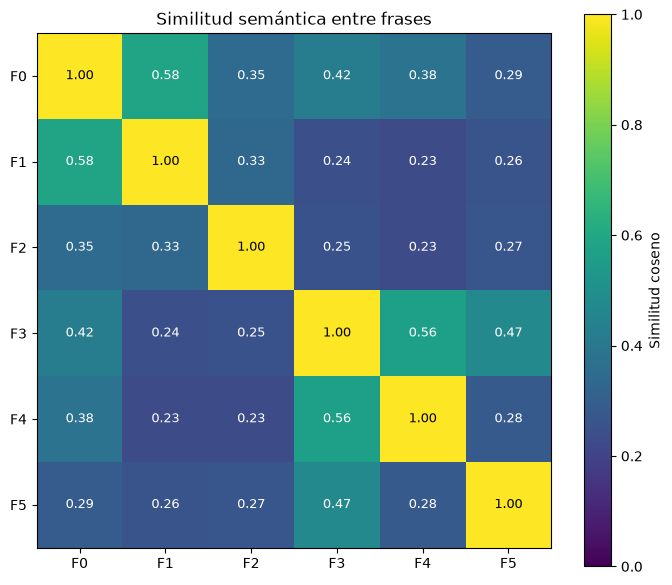

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(similitud, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(frases)))
ax.set_yticks(range(len(frases)))
ax.set_xticklabels([f"F{i}" for i in range(len(frases))])
ax.set_yticklabels([f"F{i}" for i in range(len(frases))])

# Anotar valores
for i in range(len(frases)):
    for j in range(len(frases)):
        ax.text(j, i, f"{similitud[i, j]:.2f}", ha="center", va="center",
                color="white" if similitud[i, j] < 0.6 else "black", fontsize=9)

plt.colorbar(im, ax=ax, label="Similitud coseno")
plt.title("Similitud semántica entre frases")
plt.tight_layout()
plt.show()

> 💡 La frase 0 ("Los Transformers revolucionaron NLP") se parece mucho a la frase 1 (BERT y GPT) — comparten dominio. Y nada a la frase 3 (tortilla de patatas).

---

# 3 · Aritmética semántica con GloVe

La demo clásica que hicimos en las slides: **king − man + woman ≈ queen**.

Necesitamos **embeddings de palabras sueltas** (no de frases), así que cambiamos de herramienta: usamos GloVe (Stanford, 2014), pre-entrenado sobre Wikipedia y Gigaword. La versión pequeña ocupa ~128 MB.

In [18]:
import gensim.downloader as api

# Primera vez: descarga ~128 MB. Luego está en cache.
print("⏳ Cargando GloVe (puede tardar ~30s la primera vez)...")
glove = api.load("glove-wiki-gigaword-100")  # 100-dim, ~400k palabras
print(f"✅ GloVe cargado. Vocabulario: {len(glove.key_to_index):,} palabras. Dimensión: {glove.vector_size}")

⏳ Cargando GloVe (puede tardar ~30s la primera vez)...
✅ GloVe cargado. Vocabulario: 400,000 palabras. Dimensión: 100


### La analogía clásica · rey − hombre + mujer ≈ reina

`most_similar(positive=[...], negative=[...])` calcula el vector `positive_1 + positive_2 - negative_1` y devuelve las palabras más cercanas.

In [20]:
resultado = glove.most_similar(positive=["king", "son"], negative=["man"], topn=5)

print("king - man + woman ≈ ?\n")
for palabra, score in resultado:
    print(f"  {palabra:15s} (similitud: {score:.4f})")

king - man + woman ≈ ?

  nephew          (similitud: 0.7146)
  prince          (similitud: 0.7043)
  grandson        (similitud: 0.7010)
  brother-in-law  (similitud: 0.6801)
  eldest          (similitud: 0.6793)


### Más analogías · países, plurales, verbos

Comprobamos que el patrón se mantiene en otros tipos de relación. **No** lo entrenamos para esto — emerge de la geometría.

In [21]:
analogias = [
    ("Capital",  ["paris", "italy"],    ["france"]),
    ("Plural",   ["cats", "dog"],       ["cat"]),
    ("Pasado",   ["walked", "swim"],    ["walk"]),
    ("Genero",   ["actress", "actor"],  []),
    ("País→Idi", ["spanish", "germany"], ["spain"]),
]

for etiqueta, positivos, negativos in analogias:
    pos_str = " + ".join(positivos)
    neg_str = " − " + " − ".join(negativos) if negativos else ""
    formula = pos_str + neg_str
    resultado = glove.most_similar(positive=positivos, negative=negativos, topn=1)
    print(f"[{etiqueta:8s}] {formula:40s} ≈ {resultado[0][0]:15s} ({resultado[0][1]:.3f})")

[Capital ] paris + italy − france                   ≈ rome            (0.819)
[Plural  ] cats + dog − cat                         ≈ dogs            (0.875)
[Pasado  ] walked + swim − walk                     ≈ swam            (0.748)
[Genero  ] actress + actor                          ≈ starring        (0.796)
[País→Idi] spanish + germany − spain                ≈ german          (0.930)


> **Lo que acabáis de ver** es la "magia" que en 2013 hizo a la comunidad de NLP cambiar de paradigma para siempre. La geometría captura **relaciones semánticas** sin que se las hayamos enseñado explícitamente.

---

# 4 · Visualización 2D con PCA

Los embeddings tienen 384 dimensiones (MiniLM) o 100 (GloVe). No podemos visualizarlos directamente. Los **proyectamos a 2D** con PCA, perdiendo información pero ganando intuición.

In [34]:
from sklearn.decomposition import PCA

# Lista variada de palabras de tres categorías
palabras = [
    # Animales
    "cat", "dog", "lion", "tiger", "elephant", "horse","mario","pepe",
    # Frutas
    "apple", "banana", "orange", "grape", "strawberry", "pineapple",
    # Tecnología
    "computer", "software", "internet", "algorithm", "data", "network",
]

# Filtramos las que existan en GloVe (todas deberían)
palabras = [w for w in palabras if w in glove.key_to_index]
vectores = np.array([glove[w] for w in palabras])

print(f"Vectores: {vectores.shape} (palabras × dimensiones)")

# PCA a 2 dimensiones
pca = PCA(n_components=2)
vectores_2d = pca.fit_transform(vectores)

print(f"Después de PCA: {vectores_2d.shape}")
print(f"Varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%")

Vectores: (20, 100) (palabras × dimensiones)
Después de PCA: (20, 2)
Varianza explicada: 41.0%


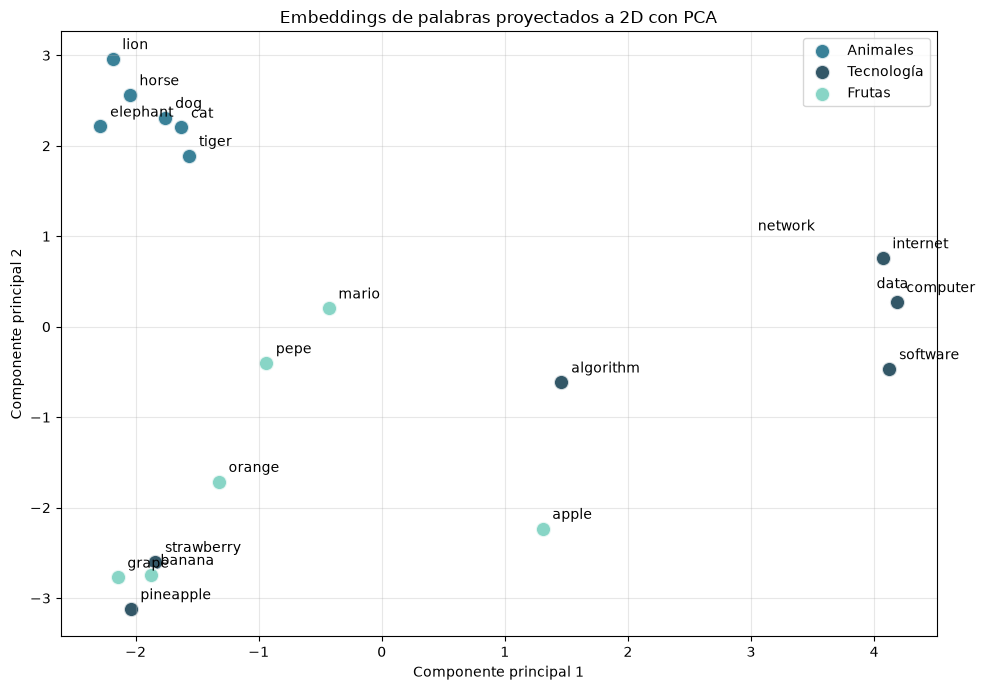

In [35]:
# Etiquetas de color por categoría
categorias = (["Animales"] * 6) + (["Frutas"] * 6) + (["Tecnología"] * 6)
colores = {"Animales": "#08627F", "Frutas": "#6ACBB8", "Tecnología": "#002D41"}

fig, ax = plt.subplots(figsize=(10, 7))
for cat in set(categorias):
    idx = [i for i, c in enumerate(categorias) if c == cat]
    ax.scatter(vectores_2d[idx, 0], vectores_2d[idx, 1],
               c=colores[cat], label=cat, s=120, alpha=0.8, edgecolors="white", linewidths=1.5)

for i, palabra in enumerate(palabras):
    ax.annotate(palabra, (vectores_2d[i, 0], vectores_2d[i, 1]),
                xytext=(7, 7), textcoords="offset points", fontsize=10)

ax.set_xlabel("Componente principal 1")
ax.set_ylabel("Componente principal 2")
ax.set_title("Embeddings de palabras proyectados a 2D con PCA")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> Tres clusters claramente separados en el plano. La geometría del espacio semántico está literalmente delante de vosotros.

---

# Cierre · Lo que hemos visto

En este notebook habéis tocado, en código real, los tres pilares del NLP moderno:

- **Tokenización** — el texto se trocea en subwords con IDs.
- **Embeddings** — cada token o frase se convierte en un vector de cientos de dimensiones.
- **Geometría semántica** — la distancia entre vectores codifica significado, y la dirección entre vectores codifica relaciones.

Todo lo que viene en el Máster (RAG, búsqueda semántica, LLMs, agentes) se construye sobre esto.

## Próximo paso · T2-S5 · Implementamos un mini-GPT

En la siguiente sesión:

- Bajamos al detalle de la arquitectura GPT (decoder-only).
- Implementamos un GPT pequeño (~10M parámetros) en vuestro MacBook M4.
- Lo entrenamos en ~10 minutos sobre un corpus pequeño.
- Generamos texto al final.

Hasta entonces.